# R7-H3 - Experimento B3: Focal Loss

**Objetivo.** Evaluar si sustituir la entropía cruzada ponderada por una Focal Loss ponderada modifica el Average Precision (AP) de ConvNeXt-Tiny con la imagen completa (representación A).

**Hipótesis (H3).** La Focal Loss reduce la contribución de los ejemplos bien clasificados con alta confianza, lo que podría favorecer el aprendizaje de los ejemplos difíciles y modificar el AP. No se presupone el sentido del cambio.

**Diseño.** Se comparan dos configuraciones con las mismas semillas (42, 43 y 44) y el mismo conjunto de validación:

| | B0 (basal) | B3 |
|---|---|---|
| Origen | Entrenamientos de R4, reutilizados en R6 (solo lectura) | Tres entrenamientos nuevos |
| Función de pérdida | Entropía cruzada ponderada | Focal Loss ponderada, γ = 2.0 |
| Pesos de clase (benigna, maligna) | ≈ 0.5610, 4.5977 (frecuencia inversa, α = 1.0) | Los mismos |

La pérdida focal es `FL = −w_y · (1 − p_t)^γ · log(p_t)`, donde `p_t` es la probabilidad asignada a la clase verdadera. Se reduce como la entropía cruzada ponderada de PyTorch (suma de pérdidas ponderadas dividida por la suma de los pesos de las muestras del batch), de modo que con γ = 0 coincide con ella; esa equivalencia se comprueba en los tests unitarios.

B3 se compara con B0, no con B2: usa los pesos originales y no los atenuados de B2. Todo lo demás es idéntico a B0: arquitectura, representación A, particiones, hiperparámetros, data augmentation, 30 épocas máximas, **early stopping activo** (paciencia 5, `min_delta` 0.001), checkpoint por máximo `val_roc_auc` y umbral 0.5. B3 se entrena desde los pesos preentrenados originales, no desde checkpoints previos.

## 1. Configuración

In [1]:
from pathlib import Path
import json
import shlex
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve


def locate_project_root() -> Path:
    current_dir = Path.cwd().resolve()

    for candidate in [current_dir, *current_dir.parents]:
        if (candidate / "src").exists() and (candidate / "data").exists():
            return candidate

    raise FileNotFoundError("No se pudo localizar la raíz del proyecto.")


PROJECT_ROOT = locate_project_root()

ARCH = "convnext_tiny"
CONDITION = "A"
SEEDS = [42, 43, 44]
EPOCHS_MAX = 30
THRESHOLD = 0.5
GAMMA = 2.0  # exponente de la Focal Loss de B3
EXPERIMENT_NAME = "r7_focal_loss"  # etiqueta que run_experiment registra en el run_config de B3

CLASSIFICATION_DIR = PROJECT_ROOT / "results" / "classification"
B0_DIR = CLASSIFICATION_DIR / "r4_benchmark" / ARCH / CONDITION  # solo lectura
B3_DIR = CLASSIFICATION_DIR / "r7_optimizacion" / "focal_loss"
ANALYSIS_DIR = B3_DIR / "analysis"
SPLIT_MANIFEST = PROJECT_ROOT / "configs" / "splits" / "mmotu_experimental_split_standard.csv"

HISTORY_KEYS = [
    "train_loss", "train_acc", "val_loss", "val_unweighted_loss", "val_acc", "val_roc_auc",
    "val_average_precision", "val_f1_malignant", "val_recall_malignant", "val_specificity", "val_balanced_accuracy",
]
# Nombres reales en los archivos: `val_loss` es la pérdida de validation del criterio de entrenamiento y la sensibilidad es `recall_malignant`
SAVED_KEYS = {"roc_auc": "roc_auc", "average_precision": "average_precision", "sensitivity": "recall_malignant", "specificity": "specificity"}

COLORS = {"B0": "#0072B2", "B3": "#CC79A7"}
LABELS = {"B0": "B0 (entropía cruzada)", "B3": f"B3 (focal, γ = {GAMMA})"}

plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})


def b0_dir(seed):
    return B0_DIR / f"seed_{seed}"


def b3_dir(seed):
    return B3_DIR / f"seed_{seed}"


def require(condition, message):
    if not condition:
        raise ValueError(message)


def compute_metrics(y_true, y_prob):
    y_true = np.asarray(y_true)
    y_pred = (np.asarray(y_prob) >= THRESHOLD).astype(int)
    fpr, tpr, _ = roc_curve(y_true, y_prob, drop_intermediate=False)
    return {
        "roc_auc": float(roc_auc_score(y_true, y_prob)),
        "average_precision": float(average_precision_score(y_true, y_prob)),
        "sensitivity": float((y_pred[y_true == 1] == 1).mean()),
        "specificity": float((y_pred[y_true == 0] == 0).mean()),
        # Mayor sensibilidad con especificidad >= 0.95 (FPR <= 0.05), sobre las predicciones guardadas; no define ningún umbral
        "sensitivity_at_spec95": float(tpr[fpr <= 0.05].max()),
    }


manifest = pd.read_csv(SPLIT_MANIFEST)
validation_manifest = manifest[manifest["experimental_split"] == "validation"].set_index("image_id")


def load_run(directory: Path, seed: int) -> dict:
    # Carga una corrida y comprueba que checkpoint, historial, predicciones y métricas sean coherentes entre sí
    with open(directory / "run_config.json", encoding="utf-8") as f:
        config = json.load(f)
    with open(directory / "training_history.json", encoding="utf-8") as f:
        raw_history = json.load(f)
    with open(directory / "validation_metrics.json", encoding="utf-8") as f:
        saved_metrics = json.load(f)
    predictions = pd.read_csv(directory / "val_predictions_best_auc.csv")

    history = pd.DataFrame({key: raw_history[key] for key in HISTORY_KEYS})
    history.index = pd.RangeIndex(1, len(history) + 1, name="epoch")

    require(config["seed"] == seed, f"{directory}: la semilla del run_config no coincide con la carpeta.")
    require(len(history) == config["epochs_run"], f"{directory}: el historial no tiene {config['epochs_run']} épocas.")
    # idxmax devuelve la primera época en caso de empate, igual que el criterio de checkpoint
    require(int(history["val_roc_auc"].idxmax()) == config["epoch_best"], f"{directory}: el checkpoint no es el máximo de val_roc_auc.")
    require(
        predictions["epoch"].eq(config["epoch_best"]).all() and len(predictions) == len(validation_manifest),
        f"{directory}: las predicciones no corresponden al checkpoint o no cubren las 200 imágenes de validation.",
    )
    labels_in_manifest = validation_manifest["binary_label"].reindex(predictions["image_id"])
    require(
        labels_in_manifest.notna().all() and (labels_in_manifest.to_numpy() == predictions["y_true"].to_numpy()).all(),
        f"{directory}: imágenes fuera de validation o etiquetas distintas del manifiesto.",
    )

    metrics = compute_metrics(predictions["y_true"], predictions["probability_malignant"])
    for metric, key in SAVED_KEYS.items():
        require(abs(metrics[metric] - saved_metrics[key]) < 1e-6, f"{directory}: {metric} recalculada no coincide con validation_metrics.json.")

    return {"config": config, "history": history, "predictions": predictions, "metrics": metrics}

## 2. Línea base B0

Se leen las configuraciones, historiales, métricas y predicciones existentes de R4. No se cargan los checkpoints `.pth` ni se modifica nada. Al cargar cada corrida se comprueba que el checkpoint sea la época de máximo `val_roc_auc`, que las predicciones sean las de esa época y que las métricas recalculadas desde ellas coincidan con `validation_metrics.json`.

In [2]:
B0 = {seed: load_run(b0_dir(seed), seed) for seed in SEEDS}

pd.DataFrame(
    [
        {
            "seed": seed,
            "épocas ejecutadas": B0[seed]["config"]["epochs_run"],
            "época del checkpoint": B0[seed]["config"]["epoch_best"],
            **{metric: round(B0[seed]["metrics"][metric], 4) for metric in [*SAVED_KEYS, "sensitivity_at_spec95"]},
        }
        for seed in SEEDS
    ]
)

,seed,épocas ejecutadas,época del checkpoint,roc_auc,average_precision,sensitivity,specificity,sensitivity_at_spec95
0,42,13,8,0.8853,0.5898,0.7727,0.7753,0.3636
1,43,8,7,0.8292,0.5295,0.3182,0.9775,0.4545
2,44,8,7,0.8156,0.5046,0.2727,0.9944,0.3182


## 3. Configuración esperada de B3 y comandos de entrenamiento

La configuración de B3 se deriva del `run_config.json` de cada semilla de B0: se conservan todos los campos de configuración, incluidos los pesos de clase y el early stopping, y solo se añaden el tipo de pérdida (`loss_type`), su exponente (`focal_gamma`) y la etiqueta del experimento. Los campos de resultado (épocas ejecutadas, época del checkpoint y valores en el checkpoint) dependen de cada corrida y no se comparan.

In [3]:
class_weights_b0 = B0[SEEDS[0]]["config"]["class_weights"]
print(f"Pesos de clase de B0 y B3 (benigna, maligna): {class_weights_b0[0]:.4f}, {class_weights_b0[1]:.4f}")

OUTCOME_FIELDS = [
    "epochs_run", "epoch_best", "val_weighted_loss_at_best_checkpoint", "val_unweighted_loss_at_best_checkpoint",
    "val_acc_at_best_checkpoint", "early_stopped", "early_stopped_at_epoch", "val_roc_auc_best",
]


def expected_b3_config(b0_config):
    expected = {key: value for key, value in b0_config.items() if key not in OUTCOME_FIELDS}
    expected.update({"experiment": EXPERIMENT_NAME, "loss_type": "focal", "focal_gamma": GAMMA})
    return expected


RUN_TRAINING = False  # True para entrenar B3 desde este notebook; False solo muestra los comandos


def b3_command(seed, python="python"):
    return [
        python, "-m", "src.classification.run_experiment",
        "--arch", ARCH, "--condition", CONDITION,
        "--experiment", EXPERIMENT_NAME, "--seed", str(seed),
        "--checkpoint-metric", "val_roc_auc",
        "--loss-type", "focal", "--focal-gamma", str(GAMMA),
        "--output-dir", b3_dir(seed).relative_to(PROJECT_ROOT).as_posix(),
    ]


print("\nComandos equivalentes para la terminal (uno por semilla):\n")
for seed in SEEDS:
    print(shlex.join(b3_command(seed)), end="\n\n")

Pesos de clase de B0 y B3 (benigna, maligna): 0.5610, 4.5977

Comandos equivalentes para la terminal (uno por semilla):

python -m src.classification.run_experiment --arch convnext_tiny --condition A --experiment r7_focal_loss --seed 42 --checkpoint-metric val_roc_auc --loss-type focal --focal-gamma 2.0 --output-dir results/classification/r7_optimizacion/focal_loss/seed_42

python -m src.classification.run_experiment --arch convnext_tiny --condition A --experiment r7_focal_loss --seed 43 --checkpoint-metric val_roc_auc --loss-type focal --focal-gamma 2.0 --output-dir results/classification/r7_optimizacion/focal_loss/seed_43

python -m src.classification.run_experiment --arch convnext_tiny --condition A --experiment r7_focal_loss --seed 44 --checkpoint-metric val_roc_auc --loss-type focal --focal-gamma 2.0 --output-dir results/classification/r7_optimizacion/focal_loss/seed_44



In [4]:
if not RUN_TRAINING:
    print("RUN_TRAINING = False: no se inicia ningún entrenamiento.")
else:
    for seed in SEEDS:
        output_dir = b3_dir(seed)
        print("=" * 80)
        print(f"Semilla {seed} -> resultados en {output_dir.relative_to(PROJECT_ROOT).as_posix()}/")

        if output_dir.exists() and any(output_dir.iterdir()):
            print("Omitida: la carpeta ya contiene archivos y no se sobrescribe. Si una corrida quedó incompleta, revísela o muévala manualmente.")
            continue

        process = subprocess.Popen(
            b3_command(seed, sys.executable), cwd=PROJECT_ROOT,
            stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, errors="replace", bufsize=1,
        )
        try:
            for line in process.stdout:
                print(line, end="")
        except KeyboardInterrupt:
            process.terminate()  # al interrumpir la celda no debe quedar un entrenamiento huérfano
            raise
        if process.wait() != 0:
            raise RuntimeError(f"El entrenamiento de la semilla {seed} terminó con error (código {process.returncode}).")

RUN_TRAINING = False: no se inicia ningún entrenamiento.


## 4. Carga y verificación de B3

Esta sección solo lee archivos y requiere que las tres corridas hayan terminado. Además de las comprobaciones internas de cada corrida (sección 1), se verifica lo necesario para que B0 y B3 sean comparables:

- la configuración de B3 coincide con la esperada (pesos de clase y early stopping incluidos), salvo el tipo de pérdida, γ, la etiqueta del experimento y los campos de resultado;
- B3 se evaluó sobre las mismas imágenes de validation, en el mismo orden, que B0.

In [5]:
B3_FILES = [
    "run_config.json", "training_history.json", "validation_metrics.json",
    "val_predictions_best_auc.csv", "best_auc_meta.json", "best_auc.pth",
]
missing = [b3_dir(seed) / name for seed in SEEDS for name in B3_FILES if not (b3_dir(seed) / name).exists()]
if missing:
    raise FileNotFoundError("Faltan salidas de B3. Complete primero los entrenamientos de la sección 3 (desde este notebook o la terminal):\n" + "\n".join(str(p) for p in missing))

B3 = {seed: load_run(b3_dir(seed), seed) for seed in SEEDS}

for seed in SEEDS:
    observed = {key: value for key, value in B3[seed]["config"].items() if key not in OUTCOME_FIELDS}
    expected = expected_b3_config(B0[seed]["config"])
    differences = {
        key: (observed.get(key), expected.get(key))
        for key in set(observed) | set(expected)
        if observed.get(key) != expected.get(key)
    }
    require(not differences, f"B3 semilla {seed}: la configuración difiere de la esperada (observado, esperado): {differences}")
    require(
        B3[seed]["predictions"]["image_id"].tolist() == B0[seed]["predictions"]["image_id"].tolist(),
        f"Semilla {seed}: B0 y B3 no se evaluaron sobre las mismas imágenes en el mismo orden.",
    )

print("B3 verificado: misma configuración que B0 salvo la función de pérdida, y mismas imágenes de validation.")

B3 verificado: misma configuración que B0 salvo la función de pérdida, y mismas imágenes de validation.


## 5. Comparación B0 frente a B3

Las métricas se calculan con las probabilidades del checkpoint de cada corrida; sensibilidad y especificidad usan el umbral 0.5. Las diferencias son emparejadas por semilla (B3 - B0). Se añade la sensibilidad con especificidad ≥ 0.95, calculada con las predicciones ya guardadas: indica cuántas malignas se detectan permitiendo como máximo 5 % de falsos positivos y no define ningún umbral. Con una pérdida distinta cambia la calibración de las probabilidades, de modo que los cambios en sensibilidad y especificidad al umbral 0.5 reflejan también ese desplazamiento; AP, ROC-AUC y la sensibilidad con especificidad ≥ 0.95 no dependen del umbral.

La tabla por semilla y el resumen (media y desviación estándar muestral entre las tres semillas) se exportan a `focal_loss/analysis/`.

In [6]:
METRICS = [*SAVED_KEYS, "sensitivity_at_spec95"]

rows = []
for seed in SEEDS:
    row = {
        "seed": seed,
        "epocas_B0": B0[seed]["config"]["epochs_run"],
        "epocas_B3": B3[seed]["config"]["epochs_run"],
        "epoca_checkpoint_B0": B0[seed]["config"]["epoch_best"],
        "epoca_checkpoint_B3": B3[seed]["config"]["epoch_best"],
    }
    for metric in METRICS:
        row[f"{metric}_B0"] = B0[seed]["metrics"][metric]
        row[f"{metric}_B3"] = B3[seed]["metrics"][metric]
        row[f"delta_{metric}"] = row[f"{metric}_B3"] - row[f"{metric}_B0"]
    rows.append(row)
per_seed = pd.DataFrame(rows)

summary = pd.DataFrame(
    [
        {
            "metrica": metric,
            "media_B0": per_seed[f"{metric}_B0"].mean(),
            "de_B0": per_seed[f"{metric}_B0"].std(ddof=1),
            "media_B3": per_seed[f"{metric}_B3"].mean(),
            "de_B3": per_seed[f"{metric}_B3"].std(ddof=1),
            "delta_medio": per_seed[f"delta_{metric}"].mean(),
            "de_delta": per_seed[f"delta_{metric}"].std(ddof=1),
        }
        for metric in METRICS
    ]
)

ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)
per_seed.to_csv(ANALYSIS_DIR / "b0_vs_b3_por_semilla.csv", index=False)
summary.to_csv(ANALYSIS_DIR / "b0_vs_b3_resumen.csv", index=False)

display(per_seed.round(4))
display(summary.round(4))

,seed,epocas_B0,epocas_B3,epoca_checkpoint_B0,epoca_checkpoint_B3,roc_auc_B0,roc_auc_B3,delta_roc_auc,average_precision_B0,average_precision_B3,delta_average_precision,sensitivity_B0,sensitivity_B3,delta_sensitivity,specificity_B0,specificity_B3,delta_specificity,sensitivity_at_spec95_B0,sensitivity_at_spec95_B3,delta_sensitivity_at_spec95
0,42,13,10,8,10,0.8853,0.8435,-0.0419,0.5898,0.4606,-0.1292,0.7727,0.4545,-0.3182,0.7753,0.9382,0.1629,0.3636,0.4545,0.0909
1,43,8,9,7,7,0.8292,0.8496,0.0204,0.5295,0.5707,0.0411,0.3182,0.4545,0.1364,0.9775,0.9775,0.0000,0.4545,0.4545,0.0000
2,44,8,9,7,8,0.8156,0.8445,0.0289,0.5046,0.6051,0.1005,0.2727,0.5455,0.2727,0.9944,0.9382,-0.0562,0.3182,0.4091,0.0909


,metrica,media_B0,de_B0,media_B3,de_B3,delta_medio,de_delta
0,roc_auc,0.8434,0.0370,0.8458,0.0033,0.0025,0.0386
1,average_precision,0.5413,0.0438,0.5454,0.0755,0.0041,0.1192
2,sensitivity,0.4545,0.2765,0.4848,0.0525,0.0303,0.3094
3,specificity,0.9157,0.1219,0.9513,0.0227,0.0356,0.1138
4,sensitivity_at_spec95,0.3788,0.0694,0.4394,0.0262,0.0606,0.0525


### 5.1 Evolución del entrenamiento

Solo se grafican las series comparables entre ambas configuraciones: la pérdida de validation sin ponderar, el AP y el ROC-AUC. `train_loss` y `val_loss` no se comparan porque corresponden a funciones de pérdida distintas (entropía cruzada ponderada en B0, Focal Loss ponderada en B3). Las líneas punteadas marcan el fin del entrenamiento de cada configuración por early stopping y las estrellas indican su checkpoint.

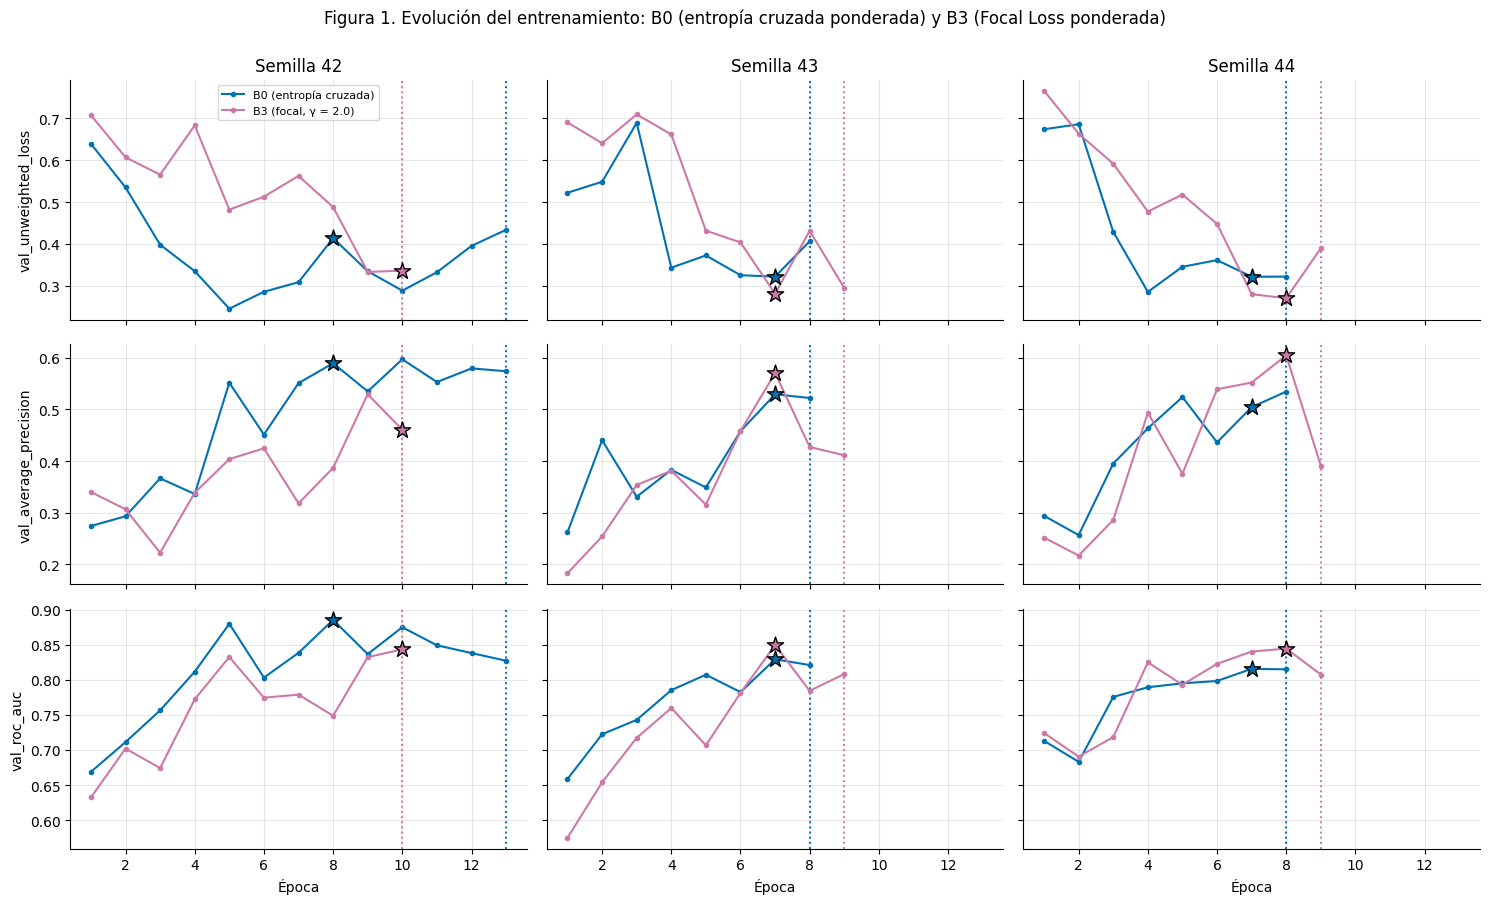

In [7]:
SERIES = [
    ("val_unweighted_loss", "val_unweighted_loss"),
    ("val_average_precision", "val_average_precision"),
    ("val_roc_auc", "val_roc_auc"),
]

fig, axes = plt.subplots(len(SERIES), len(SEEDS), figsize=(15, 9), sharex=True, sharey="row")
for col, seed in enumerate(SEEDS):
    for row, (key, label) in enumerate(SERIES):
        ax = axes[row, col]
        for tag, run in (("B0", B0[seed]), ("B3", B3[seed])):
            history, best = run["history"], run["config"]["epoch_best"]
            ax.plot(history.index, history[key], color=COLORS[tag], marker="o", ms=3, label=LABELS[tag] if row == col == 0 else None)
            ax.scatter([best], [history.loc[best, key]], marker="*", s=150, color=COLORS[tag], edgecolors="black", zorder=5)
            ax.axvline(run["config"]["epochs_run"], color=COLORS[tag], ls=":", lw=1.4)
        if row == 0:
            ax.set_title(f"Semilla {seed}")
        if col == 0:
            ax.set_ylabel(label)
        if row == len(SERIES) - 1:
            ax.set_xlabel("Época")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Figura 1. Evolución del entrenamiento: B0 (entropía cruzada ponderada) y B3 (Focal Loss ponderada)", y=1.0)
fig.tight_layout()
fig.savefig(ANALYSIS_DIR / "b0_vs_b3_curvas_entrenamiento.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.2 Average Precision por semilla

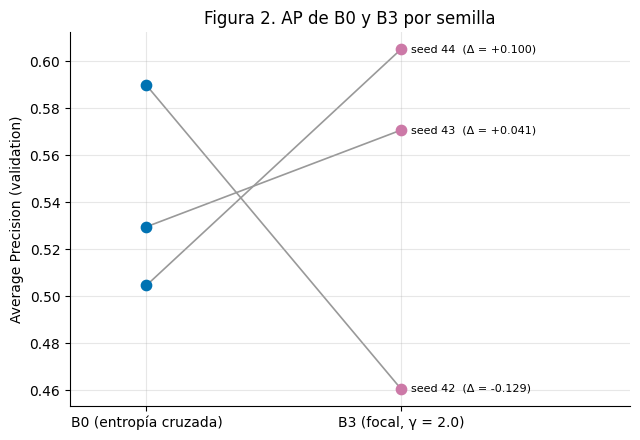

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for _, row in per_seed.iterrows():
    ax.plot([0, 1], [row["average_precision_B0"], row["average_precision_B3"]], color="0.6", lw=1.2, zorder=1)
    ax.scatter([0], [row["average_precision_B0"]], color=COLORS["B0"], s=55, zorder=3)
    ax.scatter([1], [row["average_precision_B3"]], color=COLORS["B3"], s=55, zorder=3)
    ax.annotate(f"seed {int(row['seed'])}  (Δ = {row['delta_average_precision']:+.3f})", (1.04, row["average_precision_B3"]), fontsize=8, va="center")

ax.set_xticks([0, 1])
ax.set_xticklabels([LABELS["B0"], LABELS["B3"]])
ax.set_xlim(-0.3, 1.9)
ax.set_ylabel("Average Precision (validation)")
ax.set_title("Figura 2. AP de B0 y B3 por semilla")
fig.tight_layout()
fig.savefig(ANALYSIS_DIR / "b0_vs_b3_ap_por_semilla.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.3 Pérdida sin ponderar en el checkpoint

In [9]:
pd.DataFrame(
    [
        {
            "seed": seed,
            "val_unweighted_loss en el checkpoint, B0": B0[seed]["history"].loc[B0[seed]["config"]["epoch_best"], "val_unweighted_loss"],
            "val_unweighted_loss en el checkpoint, B3": B3[seed]["history"].loc[B3[seed]["config"]["epoch_best"], "val_unweighted_loss"],
            "val_unweighted_loss mínima, B0": B0[seed]["history"]["val_unweighted_loss"].min(),
            "val_unweighted_loss mínima, B3": B3[seed]["history"]["val_unweighted_loss"].min(),
        }
        for seed in SEEDS
    ]
).round(4)

,seed,"val_unweighted_loss en el checkpoint, B0","val_unweighted_loss en el checkpoint, B3","val_unweighted_loss mínima, B0","val_unweighted_loss mínima, B3"
0,42,0.4137,0.3362,0.2455,0.3332
1,43,0.3220,0.2810,0.3220,0.2810
2,44,0.3217,0.2703,0.2855,0.2703


## 6. Limitaciones

- Son tres semillas y 22 imágenes malignas en validation: cada falso negativo equivale a 4.5 puntos de sensibilidad. Las diferencias emparejadas describen lo observado y no constituyen una prueba de efecto.
- La pérdida focal ponderada interviene también en el criterio de early stopping. Una diferencia entre B0 y B3 puede deberse a la función de pérdida, a un cambio en la época de parada o a ambos; este experimento no los separa.
- Con otra función de pérdida cambia la calibración de las probabilidades, por lo que sensibilidad y especificidad al umbral 0.5 no son estrictamente comparables entre configuraciones. No se optimiza ningún umbral.
- Solo se usa validation; los resultados no estiman el desempeño en datos no vistos. La sensibilidad con especificidad ≥ 0.95 se calcula sobre el mismo conjunto en el que se elige el checkpoint.
- El entorno de B0 no quedó registrado y el entrenamiento no fuerza el modo determinista de cuDNN: parte de la diferencia emparejada puede ser variabilidad de ejecución.
- Solo se guardan las probabilidades del checkpoint seleccionado, y no hay identificadores de paciente para verificar independencia entre imágenes.
- Este experimento no explica por qué cambian las métricas; esa interpretación corresponde a análisis posteriores.

## 7. Interpretación y conclusión

La sustitución de la entropía cruzada ponderada por Focal Loss (γ = 2.0) produjo un incremento reducido del Average Precision (AP) promedio, de 0.5413 en B0 a 0.5454 en B3, equivalente a una diferencia absoluta de +0.0041. Sin embargo, el comportamiento no fue consistente entre semillas: mientras que las semillas 43 y 44 mejoraron su AP en +0.0411 y +0.1005, respectivamente, la semilla 42 presentó una disminución de −0.1292. Asimismo, la desviación estándar del AP aumentó de 0.0438 a 0.0755.

El ROC-AUC promedio permaneció prácticamente estable (0.8434 frente a 0.8458). Por otra parte, la sensibilidad promedio al umbral 0.5 aumentó de 0.4545 a 0.4848, y la sensibilidad alcanzable con especificidad ≥ 0.95 pasó de 0.3788 a 0.4394. Estos cambios constituyen resultados secundarios favorables, aunque no uniformes entre semillas ni validados mediante un umbral operativo independiente.

La pérdida de validación sin ponderar fue menor en los checkpoints de B3 para las tres semillas, pero esta reducción no se tradujo en una mejora consistente del AP. Además, la modificación de la función de pérdida también puede influir en el comportamiento del early stopping.

En conjunto, **H3 no proporcionó evidencia suficientemente consistente de una mejora del AP respecto a B0**. Por tanto, B3 no se adopta como configuración preferida para las siguientes etapas de R7. Se mantiene B0 como referencia experimental y B2, basado en pesos de clase atenuados, como el candidato de optimización más favorable hasta el momento. Esta decisión se limita a los resultados obtenidos sobre validation.